# Installation
Installing Qiskit

In [1]:
!pip install qiskit
!pip install qiskit-ibm-runtime
!pip install 'qiskit[visualization]'
!pip install qiskit_serverless
!pip install pylatexenc

!pip install qiskit_aer

## Main task


In [2]:
import qiskit
print(qiskit.__version__)
from qiskit_ibm_runtime import QiskitRuntimeService

1.3.2


In [3]:
service = QiskitRuntimeService(channel="ibm_quantum", token = 'c287947adfd8dbbe96b534a92d0a500c22baf7995eb68cf849543a9bebd651ddf133fac90d0510ab87b8ecda5bb55c3e345945e5be113df00c45e50495440dd2')

In [4]:
backend = service.backend(name='ibm_kyiv')
print('Number of quibits:', backend.num_qubits)

Number of quibits: 127


In [5]:
from qiskit import QuantumCircuit

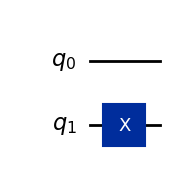

In [26]:
def Deutsch_Jozsa_Function(case):
    f = QuantumCircuit (2)
    if case in [2,3]:
        f.cx(0,1)
    if case in [3,4]:
        f.x(1)
    return f

Deutsch_Jozsa_Function(4).draw(output='mpl')

In [41]:
def circuit_creator(f):
    n = f.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)

    qc.x(n)
    qc.h(range(n + 1))

    qc.barrier()
    qc.compose(f, inplace=True)
    qc.barrier()

    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

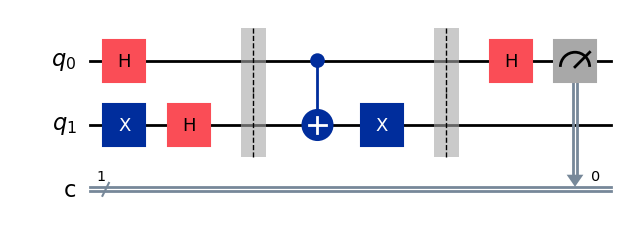

In [45]:
circuit_creator(Deutsch_Jozsa_Function(3)).draw(output='mpl')